# LSTM Practice Implementation

## Configuring MPS

In [4]:
import torch
import torch.nn as nn

#Set the device automatically: Cuda/Mps
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: mps


## Viewing the CSV

In [5]:
import pandas as pd

df = pd.read_csv("rdb5_data.csv")

df.head(5)

/var/folders/cj/rxl_zw1j7jz82tt4ktrl_w040000gn/T/ipykernel_50248/3545351190.py:3: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("rdb5_data.csv")


,ID,TIMESTAMP,OBJID,UTM_X,UTM_Y,UTM_ANGLE,V,ACC,ACC_LAT,ACC_TAN,CLASS,WIDTH,LENGTH,TRAILER_ID
0,1,0.000000,57687,617396.68,5806787.75,1.526085,7.64,0.7646,-0.7640,0.0323,Car,2.0149,4.4885,NaN
1,2,0.033367,57687,617396.69,5806788.00,1.529885,7.64,0.8675,-0.8671,0.0253,Car,2.0149,4.4885,NaN
2,3,0.066733,57687,617396.69,5806788.26,1.533185,7.64,0.9703,-0.9702,0.0158,Car,2.0149,4.4885,NaN
3,4,0.100100,57687,617396.70,5806788.51,1.536085,7.64,1.0743,-1.0743,-0.0071,Car,2.0149,4.4885,NaN
4,5,0.133467,57687,617396.70,5806788.77,1.538885,7.64,1.1802,-1.1794,-0.0434,Car,2.0149,4.4885,NaN


In [6]:
#considering vehicle classes
print(df['CLASS'].value_counts())

CLASS
Car               1262670
Pedestrian         185361
Medium Vehicle     148991
Bicycle             79396
Heavy Vehicle       38987
Trailer             33846
Bus                 14498
Motorcycle           3274
Name: count, dtype: int64


## Filtering the Data

In [7]:
#keeping only vehicle classes
vehicle_classes = [
    "Car",
    "Medium Vehicle",
    "Trailer",
    "Bus",
    "Heavy Vehicle",
    "Motorcycle"
]

df = df[df["CLASS"].isin(vehicle_classes)]

In [8]:
#verification
print(df["CLASS"].value_counts())

CLASS
Car               1262670
Medium Vehicle     148991
Heavy Vehicle       38987
Trailer             33846
Bus                 14498
Motorcycle           3274
Name: count, dtype: int64


In [9]:
#removal of less the 150 object observations
trajectory_lengths = df.groupby("OBJID").size()
valid_objids = trajectory_lengths[trajectory_lengths >= 150].index
df = df[df["OBJID"].isin(valid_objids)]

## Creating Sliding Windows

In [10]:
# #inspecting total data points amount
# positions = df[["UTM_X", "UTM_Y"]].values
# print(positions.shape)

In [11]:
# #defining input and target (first 60, next 90)
# input_positions = positions[:60]
# target_positions = positions[60:150]

# #verification
# print(input_positions.shape, target_positions.shape)

In [12]:
# #making coordinates relative to the starting point
# origin = input_positions[0]
# input_relative = input_positions - origin
# target_relative = target_positions - origin

# #verification
# print(input_relative[0])
# print(target_relative[0])

In [13]:
import numpy as np

def make_windows(positions, input_length=60, target_length=90, stride=10):
    inputs = []
    targets = []

    total_length = input_length + target_length

    for start in range(0, len(positions) - total_length + 1, stride):
        window = positions[start:start + total_length]

        #input is more than just position, output remains just position 
        input_data = window[:input_length]
        target_positions = window[input_length:]

        origin = input_data[0, :2]

        #just subtract from x and y coords, don't confuse with angle
        input_relative = input_data[:, :2] - origin
        target_relative = target_positions[:, :2] - origin

        #adding angle as a feature
        initial_angle = input_data[0, 2]
        relative_angle = input_data[:, 2] - initial_angle

        #np.sin and cos expect angle in radians
        relative_angle = np.deg2rad(relative_angle)

        #sin/cos encoding
        angle_sin = np.sin(relative_angle)
        angle_cos = np.cos(relative_angle)

        #combine x, y, sin(angle), cos(angle) together as input features
        input_features = np.column_stack((
            input_relative,
            angle_sin,
            angle_cos
        ))

        inputs.append(input_features)
        targets.append(target_relative)

    return inputs, targets

In [14]:
# inputs, targets = make_windows(positions)

# print(len(inputs))
# print(inputs[0].shape)
# print(targets[0].shape)

In [15]:
#define train, validate, test split (70/15/15) by objectID so same vehicle isn't used in train and test (cheating)
import numpy as np

#create array of only unique vehicles, to ensure all observations from the same vehicle remain in the same train, val or test set 
vehicle_ids = df["OBJID"].unique()

np.random.seed(1)

np.random.shuffle(vehicle_ids)

n = len(vehicle_ids)

#splitting the vehicle ids between sets
train_ids = vehicle_ids[:int(0.7 * n)]
val_ids = vehicle_ids[int(0.7 * n):int(0.85 * n)]
test_ids = vehicle_ids[int(0.85 * n):]

#verification
print(len(train_ids))
print(len(val_ids))
print(len(test_ids))

2808
602
602


## Making Train, Val and Test Sets

In [16]:
def create_dataset(df, vehicle_ids):
    inputs = []
    targets = []
    metadata = []

    for objid in vehicle_ids:
        #get all obserations of just one vehicle from the df
        vehicle = df[df["OBJID"] == objid]

        #get the just the features of importance (x and y pos) and now angle
        positions = vehicle[["UTM_X", "UTM_Y", "UTM_ANGLE"]].values

        #get the first 60 observations of each window and following 90.
        vehicle_inputs, vehicle_targets = make_windows(positions)

        inputs.extend(vehicle_inputs)
        targets.extend(vehicle_targets)

        #tracking where each window came from
        for start in range(0, len(positions) - 150 + 1, 10):
            metadata.append((objid, start))

    return inputs, targets, metadata

In [17]:
# defining each set through the create dataset function using the df and the specific ids attatched to each set
#now includes metadata for tracking real-world starting location 
train_inputs, train_targets, train_metadata = create_dataset(df, train_ids)
val_inputs, val_targets, val_metadata = create_dataset(df, val_ids)
test_inputs, test_targets, test_metadata = create_dataset(df, test_ids)

#validation
print("Train:", len(train_inputs))
print("Validation:", len(val_inputs))
print("Test:", len(test_inputs))

Train: 64452
Validation: 13912
Test: 13515


## Converting Data to PyTorch Tensors

In [18]:
#converting to tensors for pytorch use
train_inputs = torch.tensor(train_inputs, dtype=torch.float32)
train_targets = torch.tensor(train_targets, dtype=torch.float32)

val_inputs = torch.tensor(val_inputs, dtype=torch.float32)
val_targets = torch.tensor(val_targets, dtype=torch.float32)

test_inputs = torch.tensor(test_inputs, dtype=torch.float32)
test_targets = torch.tensor(test_targets, dtype=torch.float32)

/var/folders/cj/rxl_zw1j7jz82tt4ktrl_w040000gn/T/ipykernel_50248/2732108963.py:2: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:255.)
  train_inputs = torch.tensor(train_inputs, dtype=torch.float32)


In [19]:
# #verification
# print(train_inputs.shape)
# print(train_targets.shape)
# print(val_inputs.shape)
# print(val_targets.shape)
# print(test_inputs.shape)
# print(test_targets.shape)

## Making PyTorch Dataset

In [20]:
#the dataset stores data examples and their corresponding labels
#and gives us one example at a time
from torch.utils.data import Dataset

class TrajectoryDataset(Dataset):
    def __init__(self, inputs, targets):
        self.inputs = inputs
        self.targets = targets

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, index):
        return self.inputs[index], self.targets[index]

In [21]:
train_dataset = TrajectoryDataset(train_inputs, train_targets)
val_dataset = TrajectoryDataset(val_inputs, val_targets)
test_dataset = TrajectoryDataset(test_inputs, test_targets)

In [22]:
# x, y = train_dataset[0]

# print(x.shape)
# print(y.shape)

## Making Pytorch Dataloader

In [23]:
# DataLoader groups examples into batches
from torch.utils.data import DataLoader

# Only shuffle the training data so the model get examples
# in a different order each epoch
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

## Defining LSTM Architecture

In [24]:
class TrajectoryLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=4,
            hidden_size=128, #sensible moderate hyperparameter, however, may change during validation
            num_layers=2,
            batch_first=True
        )

        self.linear = nn.Linear(128, 180)

        #this direct-prediction architecture is a simplified starting point, sequence to sequence may be better later
        #direct prediction: predict all 90 future locations
        #sequence-to-sequence: predict future locations one at a time
        
    def forward(self, x):
        #pass the input through the LSTM
        output, (hidden, cell) = self.lstm(x)
    
        # #remove the unnecessary layer dimension ONLY works when layer dimension is 1
        # hidden = hidden.squeeze(0)

        #get just last element instead of removing first layer dimenion
        hidden = hidden[-1]
    
        #produce 180 numbers
        output = self.linear(hidden)
    
        #turn those 180 numbers into coordinates, -1 in case last batch size isn't the full 32
        output = output.reshape(-1, 90, 2)
    
        return output
        
        #If x = (32, 60, 4), then output = (32, 60, 64), hidden = (1, 32, 64), cell   = (1, 32, 64)
        # output — the hidden state at every one of the 60 input timesteps
        # hidden — the final hidden state
        # cell — the final cell state


## Instantiating Model

In [25]:
model = TrajectoryLSTM()
model = model.to(device)

## Defining Loss Function (MSE)

In [26]:
#returns PyTorch Tensor, because PyTorch needs to track the computational graph so that it can later calc gradients
#computational graph is the trail of how the value came to be input->LSTM->prediction->MSEloss
#loss.item() gives the associated float
loss_fn = nn.MSELoss()

## Optimiser

In [27]:
#utilising PyTorch's Adam Optimiser 
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## Completing One Full Training Cycle on a Batch

In [28]:
# # reset optimiser gradient
# optimizer.zero_grad()

# # make new prediction using batch
# prediction = model(x_batch)

# #calculate loss
# loss = loss_fn(prediction, y_batch)

# #calculate gradients for optimisation step
# loss.backward()

# #update weights accordingly 
# optimizer.step()

## Full Epoch

In [29]:
# model.train()

# total_loss = 0

# for x_batch, y_batch in train_loader:

#     optimizer.zero_grad()

#     prediction = model(x_batch)

#     loss = loss_fn(prediction, y_batch)

#     loss.backward()

#     optimizer.step()

#     total_loss += loss.item()

# average_loss = total_loss / len(train_loader)

# print("Training loss:", average_loss)

## Multiple Epochs

In [1443]:
num_epochs = 20
losses = []

for epoch in range(num_epochs):

    model.train()

    total_loss = 0

    for x_batch, y_batch in train_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        prediction = model(x_batch)

        loss = loss_fn(prediction, y_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    
    losses.append(average_loss)

    print("Epoch:", epoch + 1, "Training loss:", average_loss)

Epoch: 1 Training loss: 0.5854009318070731
Epoch: 2 Training loss: 0.5808850236921097
Epoch: 3 Training loss: 0.6422704479756486
Epoch: 4 Training loss: 0.6021265389457826
Epoch: 5 Training loss: 0.6006734652791367
Epoch: 6 Training loss: 0.5824847612650164
Epoch: 7 Training loss: 0.5900954240235147
Epoch: 8 Training loss: 0.5787732058142314
Epoch: 9 Training loss: 0.6091089110294583
Epoch: 10 Training loss: 0.5916354609630244
Epoch: 11 Training loss: 0.5714376792792351
Epoch: 12 Training loss: 0.6206949406832678
Epoch: 13 Training loss: 0.5623224926793545
Epoch: 14 Training loss: 0.5694224591808342
Epoch: 15 Training loss: 0.5846671060873911
Epoch: 16 Training loss: 0.5703574192952873
Epoch: 17 Training loss: 0.5770015575379946
Epoch: 18 Training loss: 0.57354244630109
Epoch: 19 Training loss: 0.5853518685173456
Epoch: 20 Training loss: 0.5705264445939667


## Graphing Loss vs Epoch

In [30]:
import matplotlib.pyplot as plt
plt.plot(range(1, num_epochs + 1), losses)

plt.xlabel("Epoch Number")
plt.ylabel("Training Loss (MSE)")
plt.title("Training Loss per Epoch")

plt.show()

NameError: name 'num_epochs' is not defined

## Model Evaluation

In [31]:
model.eval()

total_loss = 0

#no gradient calculation/ model is not changing
with torch.no_grad():

    for x_batch, y_batch in val_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        prediction = model(x_batch)

        loss = loss_fn(prediction, y_batch)

        total_loss += loss.item()

average_val_loss = total_loss / len(val_loader)

print("Validation loss:", average_val_loss)

Validation loss: 283.1359887265611


## Inference of Unseen Trajectory

In [32]:
print(len(test_inputs))
x_test = test_inputs[500]
y_test = test_targets[500]

#unsqueeze to allow a single example batch
x_test = x_test.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    prediction = model(x_test)

#remove batch dimension
prediction = prediction.squeeze(0)

13515


In [33]:
#converting tensors to np arrays for plotting
observed = x_test.squeeze(0).cpu().numpy()
actual = y_test.numpy()
predicted = prediction.cpu().numpy()

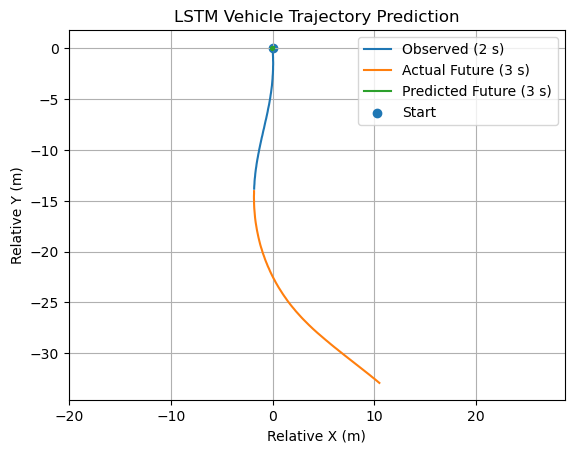

In [34]:
import matplotlib.pyplot as plt

plt.plot(observed[:, 0], observed[:, 1], label="Observed (2 s)")
plt.plot(actual[:, 0], actual[:, 1], label="Actual Future (3 s)")
plt.plot(predicted[:, 0], predicted[:, 1], label="Predicted Future (3 s)")

plt.scatter(0, 0, label="Start")

plt.xlabel("Relative X (m)")
plt.ylabel("Relative Y (m)")
plt.title("LSTM Vehicle Trajectory Prediction")

plt.axis("equal")
plt.legend()
plt.grid()

plt.show()

In [35]:
mse = loss_fn(prediction, y_test.to(device))

print("MSE:", mse.item())

MSE: 314.8818359375


In [1441]:
objid, start = test_metadata[500]

print("Vehicle:", objid)
print("Starting frame:", start)

Vehicle: 61651
Starting frame: 100


In [1433]:
vehicle = df[df["OBJID"] == objid]

positions = vehicle[["UTM_X", "UTM_Y"]].values

origin = positions[start]

observed_utm = positions[start:start + 60]

actual_utm = positions[start + 60:start + 150]

print(observed_utm[0])
print(actual_utm[-1])

print(actual_utm[-1] - observed_utm[0])

[ 617371.93 5806809.69]
[ 617382.44 5806776.77]
[ 10.51 -32.92]


## Saving Pretrained Models

In [1442]:
#Path is h<hidden layer size>_n<num_ber of layers>_e<number of epochs>_f<number_of_input_features>.pt

#model_name = "h128_n2_e80_f4.pt"
#torch.save(model.state_dict(), model_name) 

## Implementing Randomised Cyclist Trajectory

In [48]:
class Cyclist:
    #parameters will be randomised during inference
    def __init__(self, position: tuple, speed: float, direction: float):
        self.position = position #tuple of x,y location 
        self.speed = speed/3.6 #paramater of speed in km/h converted to m/s
        self.direction = np.deg2rad(direction) #parameter of direction in degrees converted to radians
        self.trajectory = self.create_trajectory()

    def create_trajectory(self):
        trajectory = []
        
        for i in range (0, 150):
            next_position = (self.position[0] + self.speed * np.cos(self.direction) * i/30, self.position[1] + self.speed * np.sin(self.direction) * i/30) 
            trajectory.append(next_position) 

        return trajectory
    
    def get_trajectory(self):
        return np.array(self.trajectory)

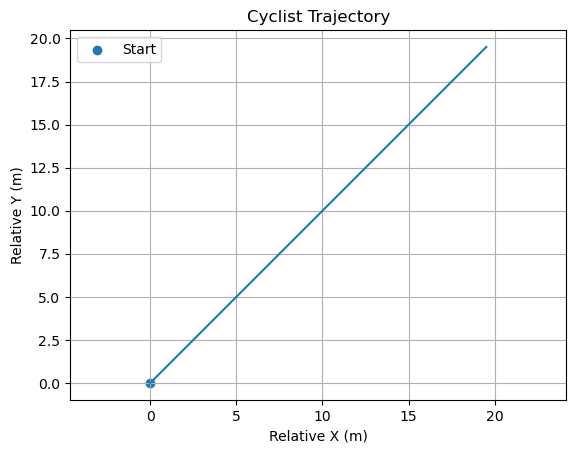

In [51]:
#Testing cyclist class implementation
cyclist = Cyclist(position=(0, 0), speed=20, direction=45)

#convert trajectory tuple list to numpy array
trajectory = cyclist.get_trajectory()

#extract coords
x = trajectory[:,0]
y = trajectory[:,1]

plt.plot(x, y)

plt.scatter(0, 0, label="Start")

plt.xlabel("Relative X (m)")
plt.ylabel("Relative Y (m)")
plt.title("Cyclist Trajectory")

plt.axis("equal")
plt.legend()
plt.grid()

plt.show()

## Time to Collision

In [38]:
#loading in pretrained model
model.load_state_dict(torch.load('h128_n2_e80_f4.pt', weights_only=True))

<All keys matched successfully>

In [56]:
vehicle_observed = test_inputs[500]
vehicle_real = test_targets[500]

#unsqueeze to allow a single example batch
vehicle_observed = vehicle_observed.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    prediction = model(vehicle_observed)

#remove batch dimension
prediction = prediction.squeeze(0)

#converting tensors to np arrays for plotting
observed = vehicle_observed.squeeze(0).cpu().numpy()
actual = vehicle_real.numpy()
predicted = prediction.cpu().numpy()

-1.9806113


In [126]:
#importing math for euclidean distance calculation
import math

#initialise cyclist
cyclist = Cyclist(position=(-20, -30), speed=20, direction=0)

tolerance = 3
crash_flagged = False

for i in range(len(predicted)):
    coordinates_distance = predicted[i] - cyclist.get_trajectory()[i+60]
    euclidean_distance = math.sqrt(coordinates_distance[0]**2 + coordinates_distance[1]**2)
    
    if euclidean_distance <= tolerance:
        print(f"Crash Risk Anticipated in {i/30} seconds")
        crash_flagged = True
        break

if not crash_flagged:
    print("No Crash Anticipated")

Crash Risk Anticipated in 2.066666666666667 seconds


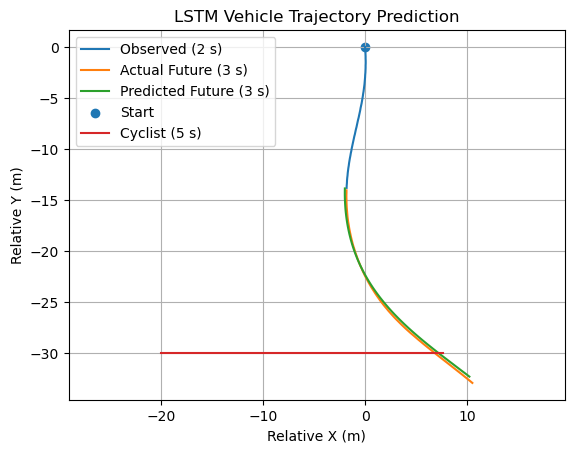

In [127]:
#Vehicle trajectory segments
plt.plot(observed[:, 0], observed[:, 1], label="Observed (2 s)")
plt.plot(actual[:, 0], actual[:, 1], label="Actual Future (3 s)")
plt.plot(predicted[:, 0], predicted[:, 1], label="Predicted Future (3 s)")

plt.scatter(0, 0, label="Start")

#Example Cyclist Trajectory
plt.plot(cyclist.get_trajectory()[:,0], cyclist.get_trajectory()[:,1], label="Cyclist (5 s)")



plt.xlabel("Relative X (m)")
plt.ylabel("Relative Y (m)")
plt.title("LSTM Vehicle Trajectory Prediction")

plt.axis("equal")
plt.legend()
plt.grid()

plt.show()